# Tarea 4: regla de resiliencia (cold start / gate de historia mínima)
**Enunciado:** el gate evalúa la cobertura histórica por centro de distribución. Con menos de 45 días de historia continua se activa un *fallback* seguro, sin excepciones; con 45 días o más se habilita el modelo complementario. Hay que argumentar con números las ventajas y riesgos de mover ese umbral.

El gate ya está implementado en `logforecast.gate` (`evaluate_gate`, `continuous_history_days`) y se usa en `GatedCorrector` (`logforecast.model`). Las funciones del estudio están en `logforecast.gate_study`. Aquí se **demuestra** y se **justifica el umbral**:

1. El gate en el tiempo: cuándo se abre en estos datos.
2. Casos borde: no lanza excepciones y cae al fallback.
3. Cold start simulado de un CD con el `GatedCorrector` real: un CD en fallback y los demás con modelo.
4. Curva de aprendizaje: WAPE según días de historia (14, 21, 28, 35, 45).
5. Error según los días de historia disponibles (todos los orígenes).
6. Simulación del sistema con gate para distintos umbrales: cobertura, WAPE e incertidumbre.

**Fallback:** el pronóstico base, sin corrección. Es seguro porque es lo que el sistema ya hace hoy.

**Limitaciones de los datos (se declaran, no se esconden):**
- Hay 60 días (1-ene a 1-mar) y los 6 CD parten el mismo día. El gate, en estos datos, se abre para todos a la vez, así que el umbral solo se puede estudiar **en el tiempo**; el cold start de un CD se simula (sección 3).
- Los 45 días solo se alcanzan al emitir desde el 15-feb. Para medir el modelo con 45 días de historia hay que mirar orígenes de la última quincena, que es también la zona de test de los notebooks 03 y 04. Aquí **no se tunea ningún modelo con ellos**: el modelo es el ElasticNet elegido en `04_validacion_cruzada_t3`, con su configuración fija (`cv.ELEGIDO`), y lo único que se estudia es la política del umbral. Aun así, es un análisis descriptivo, no un test limpio.

In [1]:
import pandas as pd

from logforecast import diagnostics, gate_study as gs, io, plots
from logforecast import features as F
from logforecast.config import Settings

AVAIL_LAG = 1      # días de rezago con que se conoce el real al emitir
MIN_DAYS = 45      # umbral exigido por el enunciado
MODELOS = gs.default_models()  # referencia ratio_mov14 y ElasticNet elegido en el notebook 04, configuración fija

S = Settings.from_env()
orders, fc = io.load_orders(S), io.load_forecasts(S)
frame = diagnostics.build_eval_frame(orders, fc)
frame[F.DESP] = pd.to_datetime(frame[F.DESP])
frame[F.EMI] = pd.to_datetime(frame[F.EMI])
CDS = sorted(frame[F.CD].unique())
feat = F.build_features(frame, avail_lag=AVAIL_LAG)

hist = gs.history_frame(orders)  # una fila por (CD, día): es lo que mira el gate
gs.history_summary(hist)

,desde,hasta,dias_con_datos,dias_calendario,huecos
centro_distribucion,,,,,
CD_CENTRO,2026-01-01,2026-03-01,60,60,0
CD_ESTE,2026-01-01,2026-03-01,60,60,0
CD_NORTE,2026-01-01,2026-03-01,60,60,0
CD_OESTE,2026-01-01,2026-03-01,60,60,0
CD_PACIFICO,2026-01-01,2026-03-01,60,60,0
CD_SUR,2026-01-01,2026-03-01,60,60,0


## 1. El gate en el tiempo
`continuous_history_days` cuenta los días consecutivos que terminan en la última fecha con datos (un hueco reinicia la cuenta). Al emitir en `t` solo se conoce el real hasta `t - AVAIL_LAG`, por eso el gate se evalúa con `as_of = t - AVAIL_LAG`.

In [2]:
fechas_ref = ["2026-01-21", "2026-02-13", "2026-02-14", "2026-02-28"]
display(pd.concat({f: gs.gate_state(hist, f, CDS, MIN_DAYS) for f in fechas_ref}, names=["as_of", "CD"]))

primero = gs.first_open_date(hist, CDS, MIN_DAYS, AVAIL_LAG, "2026-01-02", "2026-03-01")
print(f"Primer día de emisión con el gate abierto en todos los CD: {primero:%Y-%m-%d} "
      f"(real conocido hasta {primero - pd.Timedelta(days=AVAIL_LAG):%Y-%m-%d})")

dias    estado
as_of      CD                        
2026-01-21 CD_CENTRO     21  FALLBACK
           CD_ESTE       21  FALLBACK
           CD_NORTE      21  FALLBACK
           CD_OESTE      21  FALLBACK
           CD_PACIFICO   21  FALLBACK
           CD_SUR        21  FALLBACK
2026-02-13 CD_CENTRO     44  FALLBACK
           CD_ESTE       44  FALLBACK
           CD_NORTE      44  FALLBACK
           CD_OESTE      44  FALLBACK
           CD_PACIFICO   44  FALLBACK
           CD_SUR        44  FALLBACK
2026-02-14 CD_CENTRO     45     TRAIN
           CD_ESTE       45     TRAIN
           CD_NORTE      45     TRAIN
           CD_OESTE      45     TRAIN
           CD_PACIFICO   45     TRAIN
           CD_SUR        45     TRAIN
2026-02-28 CD_CENTRO     59     TRAIN
           CD_ESTE       59     TRAIN
           CD_NORTE      59     TRAIN
           CD_OESTE      59     TRAIN
           CD_PACIFICO   59     TRAIN
           CD_SUR        59     TRAIN

Primer día de emisión con el gate abierto en todos los CD: 2026-02-15 (real conocido hasta 2026-02-14)


## 2. Casos borde: nunca lanza excepciones
Ante historia vacía, un CD sin datos, huecos, duplicados o una columna faltante, el gate devuelve decisiones (o un diccionario vacío) y el sistema cae al fallback.

In [3]:
gs.edge_cases(hist, CDS, "2026-02-28", MIN_DAYS)

gate fallo globalmente: 'fecha_despacho'


,excepción,decisiones,en TRAIN,en FALLBACK
historia vacía,no,6,0,"CD_CENTRO (0d), CD_ESTE (0d), CD_NORTE (0d), C..."
CD sin datos (CD_CENTRO),no,6,5,CD_CENTRO (0d)
hueco el 10-feb en CD_ESTE,no,6,5,CD_ESTE (18d)
filas duplicadas,no,6,6,-
columna de fecha faltante,no,0,0,todos (sin decisión)


## 3. Cold start simulado con el `GatedCorrector` real
Se simula que el último CD empezó a operar el 1-feb (se descarta su historia anterior). Se entrena con lo conocido hasta el 27-feb y se predice lo emitido el 28-feb. Ese CD debe quedar en fallback (pronóstico base, sin tocar) y los demás con el corrector (aquí el `ElasticNetCorrector`, el mismo modelo complementario que usa el pipeline de producción).

In [4]:
decisiones, chequeo = gs.cold_start_demo(frame, CDS, CDS[-1], "2026-02-01", "2026-02-28", MIN_DAYS, AVAIL_LAG)
display(decisiones)
chequeo

,status,continuous_days,min_days,reason
CD_CENTRO,TRAIN,57,45,historia suficiente
CD_ESTE,TRAIN,57,45,historia suficiente
CD_NORTE,TRAIN,57,45,historia suficiente
CD_OESTE,TRAIN,57,45,historia suficiente
CD_PACIFICO,TRAIN,57,45,historia suficiente
CD_SUR,FALLBACK,27,45,historia insuficiente (27 < 45 dias)


,filas,pred == base,factor medio
CD_CENTRO,1,False,0.838779
CD_ESTE,1,False,1.276574
CD_NORTE,1,False,1.186884
CD_OESTE,1,False,0.918599
CD_PACIFICO,1,False,0.795008
CD_SUR,1,True,1.0


## 4. Curva de aprendizaje: WAPE según días de historia de entrenamiento
En cada origen se reentrena usando solo los últimos **N días** de reales conocidos (ventana móvil), con N = 14, 21, 28, 35 y 45, y también con toda la historia. N limita las **filas de entrenamiento**; las features rolling siguen mirando todo el pasado causal. Se evalúan los orígenes del 15 al 28-feb, los únicos con al menos 45 días disponibles, de modo que todas las ventanas se comparan sobre **las mismas filas**.

Modelos: `ratio_mov14` (la referencia; por construcción usa solo los últimos 14 días, así que con N ≥ 14 su curva es plana) y `enet` (el ElasticNet elegido en el notebook 04, configuración fija), contra el `base`.

In [5]:
ORIG_A = pd.date_range("2026-02-15", "2026-02-28")
VENTANAS = [14, 21, 28, 35, 45, None]

curva, n_filas = gs.learning_curve(feat, ORIG_A, VENTANAS, AVAIL_LAG, MODELOS)
print(f"filas evaluadas: {n_filas} (orígenes {ORIG_A[0]:%d-%b} a {ORIG_A[-1]:%d-%b})")
display((curva * 100).round(2))
(curva.drop(columns="base").sub(curva["base"], axis=0) * 100).round(2).rename(columns=lambda c: f"{c} - base (pp)")

filas evaluadas: 300 (orígenes 15-Feb a 28-Feb)


,base,ratio_mov14,enet
días de historia (ventana),,,
14,20.43,8.91,7.59
21,20.43,8.91,7.36
28,20.43,8.91,7.39
35,20.43,8.91,7.31
45,20.43,8.91,7.44
todo,20.43,8.91,7.28


,ratio_mov14 - base (pp),enet - base (pp)
días de historia (ventana),,
14,-11.52,-12.84
21,-11.52,-13.07
28,-11.52,-13.04
35,-11.52,-13.12
45,-11.52,-12.99
todo,-11.52,-13.15


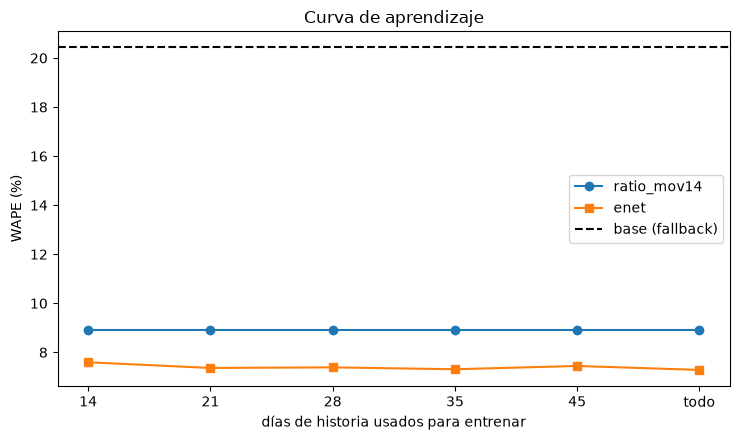

In [6]:
plots.plot_learning_curve(curva)

## 5. Qué pasa según los días de historia disponibles (todos los orígenes)
Con ventana expansiva (entrena con todo lo conocido) y orígenes desde el 15-ene (14 días de historia) hasta el 28-feb (58 días), se agrupa el error por **días de historia continua al emitir**, calculados con el mismo `evaluate_gate`. Así se ve si el modelo ya le gana al base con poca historia o solo cuando hay más.

In [7]:
ORIG_ALL = pd.date_range("2026-01-15", "2026-02-28")
D, tabla_tramos = gs.backtest_by_history(feat, hist, CDS, ORIG_ALL, AVAIL_LAG, MODELOS)
tabla_tramos.round(2)

,orígenes,filas,base,ratio_mov14,enet,ratio_mov14 - base (pp),enet - base (pp)
días de historia,,,,,,,
14-20,7.0,168.0,21.80,9.87,8.13,-11.93,-13.67
21-27,7.0,168.0,20.58,9.92,7.78,-10.66,-12.80
28-34,7.0,168.0,20.73,9.46,8.62,-11.27,-12.11
35-44,10.0,240.0,21.11,9.71,7.46,-11.40,-13.65
45+,14.0,300.0,20.43,8.91,7.28,-11.52,-13.15


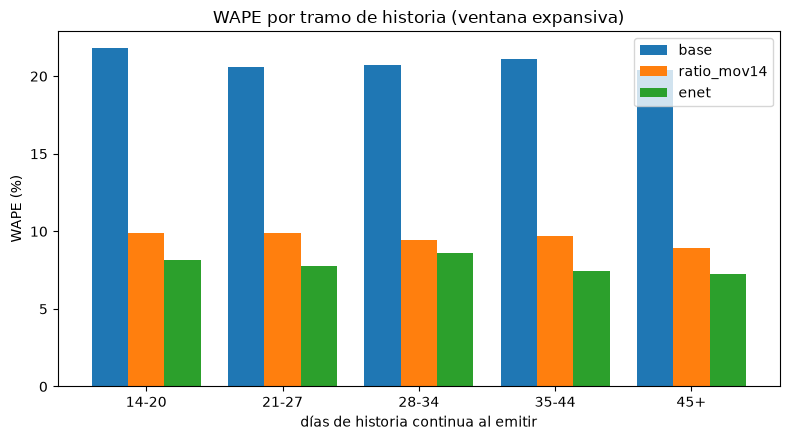

In [8]:
plots.plot_tramos(tabla_tramos)

## 6. Sistema con gate: cobertura, WAPE e incertidumbre para distintos umbrales
Para cada umbral `T` se aplica el gate real en cada origen: los CD con al menos `T` días usan el modelo y el resto el base. Se mide:
- **cobertura:** % de filas atendidas por el modelo (el resto va a fallback);
- **WAPE** del sistema con gate, y su diferencia contra el base y contra el modelo sin gate;
- **IC 90 % de la diferencia con el base:** remuestreo de orígenes con reemplazo (500 réplicas). Los orígenes consecutivos son dependientes, así que es una guía y no un intervalo exacto.

Si abrir pronto empeora el WAPE contra el base, el umbral protege; si no cambia, un umbral alto solo desperdicia cobertura.

In [9]:
UMBRALES = [14, 21, 28, 35, 45, 52]
abierto = gs.open_status(hist, CDS, ORIG_ALL, UMBRALES, AVAIL_LAG)

base_w = gs.wape(D, "pred_base")
print(f"filas: {len(D)} | base: {base_w * 100:.2f}% | "
      + " | ".join(f"{n} sin gate: {gs.wape(D, f'pred_{n}') * 100:.2f}%" for n in MODELOS))

sims = {n: gs.simulate_thresholds(D, abierto, n) for n in MODELOS}
for nombre, t in sims.items():
    print(f"\nGate con {nombre}:")
    display(t.round(2))

filas: 1044 | base: 20.88% | ratio_mov14 sin gate: 9.50% | enet sin gate: 7.75%

Gate con ratio_mov14:


,cobertura (%),WAPE gate (%),vs base (pp),vs modelo sin gate (pp),IC90 vs base (pp)
umbral T (días),,,,,
14,100.0,9.498686,-11.382235,0.0,"[-11.89, -10.89]"
21,83.908046,11.414762,-9.466159,1.916076,"[-10.53, -8.28]"
28,67.816092,13.095822,-7.785099,3.597136,"[-9.10, -6.52]"
35,51.724138,14.916661,-5.96426,5.417974,"[-7.31, -4.52]"
45,28.735632,17.582138,-3.298783,8.083451,"[-4.53, -2.01]"
52,12.643678,19.353977,-1.526944,9.855291,"[-2.48, -0.54]"



Gate con enet:


,cobertura (%),WAPE gate (%),vs base (pp),vs modelo sin gate (pp),IC90 vs base (pp)
umbral T (días),,,,,
14,100.0,7.753567,-13.127354,0.0,"[-13.65, -12.65]"
21,83.908046,9.948968,-10.931953,2.195402,"[-12.16, -9.64]"
28,67.816092,11.967143,-8.913778,4.213576,"[-10.47, -7.44]"
35,51.724138,13.924665,-6.956256,6.171098,"[-8.47, -5.26]"
45,28.735632,17.11731,-3.763611,9.363744,"[-5.18, -2.31]"
52,12.643678,19.143761,-1.73716,11.390195,"[-2.83, -0.64]"


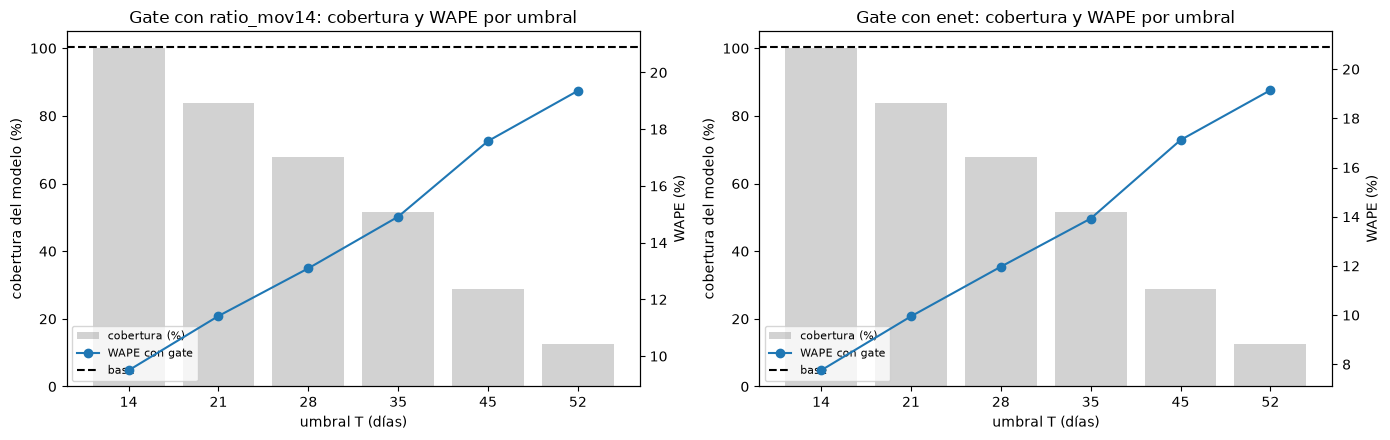

In [10]:
plots.plot_threshold_sim(sims, base_w)

## Ventajas y riesgos de ajustar el umbral
Las cifras salen de las tablas de las secciones 4 a 6 (modelo: ElasticNet; referencia: `ratio_mov14`).

**Qué muestran los datos**
- **El modelo no necesita 45 días para ganarle al base.** En la curva de aprendizaje (mismas 300 filas, orígenes 15 al 28-feb), el ElasticNet entrenado con solo 14 días tiene WAPE 7,59% contra 20,43% del base; con 21 días, 7,36%, y con toda la historia, 7,28%. Desde 21 días la diferencia con toda la historia es de décimas y no es monótona (45 días: 7,44%; 35 días: 7,31%).
- **Tampoco empeora con poca historia.** Por tramo de historia al emitir, el ElasticNet le gana al base en todos los tramos por al menos 12 pp, incluido el de 14–20 días (8,13% contra 21,80%). El peor tramo es 28–34 días (8,62%).
- **Subir el umbral solo quita cobertura.** Con todos los CD partiendo el mismo día, el sistema con gate pasa de 100% de cobertura y WAPE 7,75% (T = 14) a 28,7% de cobertura y WAPE 17,12% con T = 45: en este período, el umbral de 45 días deja 9,4 pp de mejora sin usar (columna "vs modelo sin gate"). El IC 90% de la diferencia con el base queda bajo cero para todos los umbrales probados: en ningún caso abrir antes empeora al base.

**Subir el umbral (más exigente, p. ej. 45 → 60)**
- *Ventaja:* parámetros estimados con más historia, menos riesgo de que un CD nuevo reciba una corrección mal estimada.
- *Riesgo:* menos cobertura; en estos datos, cada umbral más alto aleja el WAPE del sistema del 7,75% alcanzable y lo acerca al 20,88% del base. En un CD nuevo, el costo son semanas o meses sin corrección.

**Bajar el umbral (más permisivo, p. ej. 45 → 21)**
- *Ventaja:* la corrección llega antes; en estos datos, con T = 21 la cobertura sube a 83,9% y el WAPE del sistema baja a 9,95%.
- *Riesgo:* con pocas filas los coeficientes son más inestables y aquí no se puede medir bien (ver abajo). Además hay un mínimo técnico: `pico_margen` necesita 14 días de reales (mínimo para estimar el umbral de pico) y `lag7_rel`, 7 días; con menos de ~15 días esas features quedan imputadas en 0 y el modelo pierde información.

**Criterio sugerido.** El umbral mínimo con el que el modelo no es peor que el base (límite superior del IC de "vs base" ≤ 0) y su WAPE ya se estabilizó en la curva de aprendizaje. En estos datos ambas condiciones se cumplen desde 21 días (3 semanas completas, lo que cubre `lag7_rel` y el día de la semana). Se implementa 45 porque lo exige el enunciado y es una posición conservadora, pero los datos indican que el umbral se puede bajar; debe ser configurable (`LF_MIN_HISTORY_DAYS`) y revisarse en producción con más historia.

**Lo que este análisis no puede decir:**
- Con 60 días y un inicio común, no se puede medir el efecto del umbral por CD ni la sensibilidad a un CD con historia irregular; eso se simuló en la sección 3.
- Los 45 días solo se observan en las últimas 2 semanas, que coinciden con la zona de test de los notebooks 03 y 04: las diferencias de décimas de punto no son concluyentes.
- El tramo más corto probado es 14 días: por debajo no hay datos para medir.
- No hay estacionalidad anual ni feriados en la muestra.